# VCU Torque Analysis

This notebook loads one decoded `MEAS####.csv`/`DERI####.csv` session, aligns medium-rate power samples with the nearest fast RPM and commanded-torque samples, calculates torque from power and RPM, and plots calculated torque against commanded torque.

## Imports

In [1]:
from pathlib import Path
import math
import re

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## User Configuration

In [67]:
# Directory created by vcu_bin_to_csv.py.
DATA_DIR = Path("converted-3")

# Select the numeric suffix of MEAS####.csv and DERI####.csv.
# Also accepts strings such as "0132", "LOG0132", or "MEAS0132.csv".
LOG_NUMBER = 191

# Medium power samples are paired with the nearest fast torque/RPM sample within this tolerance.
MAX_MATCH_DELTA_MS = 75

# Torque from power/RPM is unstable near zero speed, so low-RPM rows are dropped.
MIN_ABS_RPM = 50

# Ratio plots drop rows where commanded torque is too close to zero.
MIN_ABS_COMMANDED_TORQUE_FOR_RATIO = 5.0

# Set to an integer to downsample the scatter plot, or leave as None to plot all valid pairs.
MAX_SCATTER_POINTS = None

# Heatmap settings for the RPM-binned torque comparison plot.
RPM_HEATMAP_BINS = 8
TORQUE_HEATMAP_BINS = 50

# RPM bins for the average torque dot plot.
AVG_TORQUE_RPM_BINS = 50


## Helper Functions

In [68]:
LOG_ID_RE = re.compile(r"^(?:(?:LOG|MEAS|DERI|CELL))?(?P<num>\d+)(?:\.CSV)?$", re.IGNORECASE)
LOG_FILE_RE = re.compile(r"^(?P<source>MEAS|DERI|CELL)(?P<num>\d+)\.csv$", re.IGNORECASE)
SOURCES = ("MEAS", "DERI", "CELL")


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "vcu_bin_to_csv.py").exists():
            return path
    return start


REPO_ROOT = find_repo_root()


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def format_log_id(log_number):
    text = str(log_number).strip()
    match = LOG_ID_RE.fullmatch(text)
    if match is None:
        raise ValueError(f"Invalid log number: {log_number!r}")
    number = int(match.group("num"))
    return f"LOG{number:04d}", number


def _with_elapsed_seconds(df, time_origin):
    df = df.copy()
    time_seconds = pd.to_numeric(df["time_seconds"], errors="coerce")
    location = df.columns.get_loc("time_seconds") + 1
    df.insert(location, "elapsed_s", time_seconds - time_origin)
    return df


def load_single_vcu_log(data_dir, log_number, required_sources=("MEAS", "DERI")):
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.is_dir():
        raise FileNotFoundError(f"Directory not found: {data_dir}")

    log_id, numeric_id = format_log_id(log_number)
    files = {}
    for path in sorted(data_dir.glob("*.csv")):
        match = LOG_FILE_RE.fullmatch(path.name)
        if match is None or int(match.group("num")) != numeric_id:
            continue
        source = match.group("source").upper()
        if source in files:
            raise ValueError(f"Duplicate {source} file for log {numeric_id}: {path}")
        files[source] = path

    missing = [source for source in required_sources if source not in files]
    if missing:
        missing_files = ", ".join(f"{source}{numeric_id:04d}.csv" for source in missing)
        raise FileNotFoundError(f"Missing required CSV file(s): {missing_files}")

    raw_data = {source: pd.read_csv(path, low_memory=False) for source, path in files.items()}
    starts = []
    for source, frame in raw_data.items():
        require_columns(frame, source, ["time_seconds"])
        times = pd.to_numeric(frame["time_seconds"], errors="coerce").dropna()
        if not times.empty:
            starts.append(times.min())
    time_origin = min(starts) if starts else 0.0
    data = {source: _with_elapsed_seconds(frame, time_origin) for source, frame in raw_data.items()}

    print(f"Loaded {log_id} from {data_dir}")
    for source in sorted(data, key=SOURCES.index):
        counts = data[source]["record_type"].value_counts().to_dict() if "record_type" in data[source] else {}
        count_text = ", ".join(f"{name}={count:,}" for name, count in counts.items())
        print(f"  {source}: {len(data[source]):,} rows ({count_text}) [{files[source].name}]")

    return {
        "log_id": log_id,
        "numeric_id": numeric_id,
        "directory": data_dir,
        "files": files,
        "data": data,
        "time_origin_seconds": time_origin,
    }


def _numeric(series):
    return pd.to_numeric(series, errors="coerce")


def require_columns(df, stream, columns):
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise KeyError(f"{stream} CSV is missing required column(s): {', '.join(missing)}")


## Torque Calculation

In [69]:
def build_torque_pairs(log, max_match_delta_ms=75, min_abs_rpm=50):
    measured = log["data"]["MEAS"]
    derived = log["data"]["DERI"]
    require_columns(measured, "MEAS", ["record_type", "time_seconds", "motor_rpm"])
    require_columns(derived, "DERI", ["record_type", "time_seconds", "commanded_torque_nm", "power_kw"])

    measured_fast = measured.loc[measured["record_type"].astype(str).str.lower().eq("fast")]
    derived_fast = derived.loc[derived["record_type"].astype(str).str.lower().eq("fast")]
    derived_medium = derived.loc[derived["record_type"].astype(str).str.lower().eq("medium")]

    rpm_signals = pd.DataFrame(
        {
            "rpm_t_ms": _numeric(measured_fast["time_seconds"]) * 1000.0,
            "motor_rpm": _numeric(measured_fast["motor_rpm"]),
        }
    ).dropna(subset=["rpm_t_ms"]).sort_values("rpm_t_ms")

    commanded_signals = pd.DataFrame(
        {
            "fast_t_ms": _numeric(derived_fast["time_seconds"]) * 1000.0,
            "commanded_torque_nm": _numeric(derived_fast["commanded_torque_nm"]),
        }
    ).dropna(subset=["fast_t_ms"]).sort_values("fast_t_ms")

    fast_signals = pd.merge_asof(
        commanded_signals,
        rpm_signals,
        left_on="fast_t_ms",
        right_on="rpm_t_ms",
        direction="nearest",
        tolerance=max_match_delta_ms,
    )
    fast_signals["rpm_match_delta_ms"] = fast_signals["fast_t_ms"] - fast_signals["rpm_t_ms"]

    medium_signals = pd.DataFrame(
        {
            "power_t_ms": _numeric(derived_medium["time_seconds"]) * 1000.0,
            "power_kw": _numeric(derived_medium["power_kw"]),
        }
    ).dropna(subset=["power_t_ms"]).sort_values("power_t_ms")

    aligned = pd.merge_asof(
        medium_signals,
        fast_signals,
        left_on="power_t_ms",
        right_on="fast_t_ms",
        direction="nearest",
        tolerance=max_match_delta_ms,
    )
    aligned["match_delta_ms"] = aligned["power_t_ms"] - aligned["fast_t_ms"]

    angular_velocity_rad_s = aligned["motor_rpm"] * (2.0 * math.pi / 60.0)
    aligned["calculated_torque_nm"] = (aligned["power_kw"] * 1000.0) / angular_velocity_rad_s
    aligned["torque_error_nm"] = aligned["calculated_torque_nm"] - aligned["commanded_torque_nm"]
    aligned["abs_torque_error_nm"] = aligned["torque_error_nm"].abs()

    valid = aligned[
        aligned["fast_t_ms"].notna()
        & aligned["power_kw"].notna()
        & aligned["commanded_torque_nm"].notna()
        & aligned["motor_rpm"].notna()
        & (aligned["motor_rpm"].abs() >= min_abs_rpm)
        & np.isfinite(aligned["calculated_torque_nm"])
    ].copy()

    valid["elapsed_s"] = (valid["power_t_ms"] - valid["power_t_ms"].min()) / 1000.0
    return valid.reset_index(drop=True)


def summarize_torque_pairs(torque_pairs):
    if torque_pairs.empty:
        return pd.DataFrame(
            [{"metric": "valid_pairs", "value": 0, "unit": "rows"}]
        )

    error = torque_pairs["torque_error_nm"]
    rows = [
        ("valid_pairs", len(torque_pairs), "rows"),
        ("mean_commanded_torque", torque_pairs["commanded_torque_nm"].mean(), "Nm"),
        ("max_commanded_torque", torque_pairs["commanded_torque_nm"].max(), "Nm"),
        ("mean_calculated_torque", torque_pairs["calculated_torque_nm"].mean(), "Nm"),
        ("max_calculated_torque", torque_pairs["calculated_torque_nm"].max(), "Nm"),
        ("mean_error", error.mean(), "Nm"),
        ("mean_absolute_error", error.abs().mean(), "Nm"),
        ("rmse", np.sqrt(np.mean(error ** 2)), "Nm"),
        ("correlation", torque_pairs["commanded_torque_nm"].corr(torque_pairs["calculated_torque_nm"]), ""),
    ]
    return pd.DataFrame(rows, columns=["metric", "value", "unit"])


## Plotters

In [70]:
def _scatter_sample(df, max_points=None):
    if max_points is None or len(df) <= max_points:
        return df
    return df.sample(max_points, random_state=0).sort_values("power_t_ms")


def _torque_axis_limits(torque_pairs):
    x = torque_pairs["commanded_torque_nm"]
    y = torque_pairs["calculated_torque_nm"]
    lower = min(x.min(), y.min(), 0)
    upper = max(x.max(), y.max(), 0)
    span = upper - lower
    pad = span * 0.05 if span else 1.0
    return lower - pad, upper + pad


def plot_torque_scatter(torque_pairs, log_id=None, max_points=None, color_by="motor_rpm"):
    if torque_pairs.empty:
        raise ValueError("No valid torque pairs to plot. Try lowering MIN_ABS_RPM or increasing MAX_MATCH_DELTA_MS.")

    plot_df = _scatter_sample(torque_pairs, max_points=max_points)
    x = plot_df["commanded_torque_nm"]
    y = plot_df["calculated_torque_nm"]

    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    scatter_kwargs = {"s": 22, "alpha": 0.75, "edgecolors": "none"}
    if color_by in plot_df.columns:
        points = ax.scatter(x, y, c=plot_df[color_by], cmap="viridis", **scatter_kwargs)
        cbar = fig.colorbar(points, ax=ax)
        cbar.set_label(color_by)
    else:
        ax.scatter(x, y, **scatter_kwargs)

    lower, upper = _torque_axis_limits(plot_df)
    ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1.0, label="1:1")
    ax.set_xlim(max(0.0, lower), upper)
    ax.set_ylim(max(0.0, lower), upper)

    title = "Calculated torque vs commanded torque"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Commanded torque (Nm)")
    ax.set_ylabel("Calculated torque from power/RPM (Nm)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


def remove_outliers(df, column, lower_pct=1.0, upper_pct=97.0):
    """Remove outliers by trimming percentiles - very robust to skewed data"""
    lower_bound = df[column].quantile(lower_pct / 100)
    upper_bound = df[column].quantile(upper_pct / 100)
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    

def torque_ratio_pairs(torque_pairs, min_abs_commanded_torque=1.0):
    plot_df = torque_pairs.dropna(
        subset=["motor_rpm", "commanded_torque_nm", "calculated_torque_nm"]
    ).copy()
    if plot_df.empty:
        return plot_df

    plot_df = plot_df[plot_df["commanded_torque_nm"].abs() >= min_abs_commanded_torque].copy()
    plot_df = plot_df[plot_df["motor_rpm"] >= 0.0].copy()
    plot_df["torque_ratio_calc_over_cmd"] = (
        plot_df["calculated_torque_nm"] / plot_df["commanded_torque_nm"]
    )
    plot_df = plot_df.replace([np.inf, -np.inf], np.nan)
    plot_df = plot_df.dropna(subset=["torque_ratio_calc_over_cmd"])
    return remove_outliers(plot_df, "torque_ratio_calc_over_cmd")


def plot_torque_ratio_vs_rpm_scatter(
    torque_pairs,
    log_id=None,
    max_points=None,
    min_abs_commanded_torque=1.0,
):
    plot_df = torque_ratio_pairs(
        torque_pairs,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if plot_df.empty:
        raise ValueError("No valid torque ratios to plot. Try lowering MIN_ABS_COMMANDED_TORQUE_FOR_RATIO.")

    plot_df = _scatter_sample(plot_df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        plot_df["motor_rpm"],
        plot_df["torque_ratio_calc_over_cmd"],
        s=22,
        alpha=0.65,
        edgecolors="none",
        label="Calculated / commanded",
    )
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="1.0 ratio")

    title = "Calculated/commanded torque ratio vs RPM"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Motor RPM")
    ax.set_ylabel("Calculated / commanded torque")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


def average_torque_ratio_by_rpm_bin(torque_pairs, rpm_bins=24, min_abs_commanded_torque=1.0):
    plot_df = torque_ratio_pairs(
        torque_pairs,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if plot_df.empty:
        return pd.DataFrame()

    rpm_min = plot_df["motor_rpm"].min()
    rpm_max = plot_df["motor_rpm"].max()
    if rpm_max <= rpm_min:
        rpm_edges = np.array([rpm_min - 0.5, rpm_max + 0.5])
    else:
        rpm_edges = np.linspace(rpm_min, rpm_max, rpm_bins + 1)

    plot_df["rpm_bin"] = pd.cut(plot_df["motor_rpm"], bins=rpm_edges, include_lowest=True)
    grouped = plot_df.groupby("rpm_bin", observed=True).agg(
        rpm_mid=("motor_rpm", "mean"),
        avg_torque_ratio_calc_over_cmd=("torque_ratio_calc_over_cmd", "mean"),
        median_torque_ratio_calc_over_cmd=("torque_ratio_calc_over_cmd", "median"),
        samples=("motor_rpm", "size"),
    )
    return grouped.reset_index()


def plot_average_torque_ratio_by_rpm(
    torque_pairs,
    log_id=None,
    rpm_bins=24,
    min_abs_commanded_torque=1.0,
):
    avg_df = average_torque_ratio_by_rpm_bin(
        torque_pairs,
        rpm_bins=rpm_bins,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if avg_df.empty:
        raise ValueError("No valid torque ratios to average by RPM bin.")

    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        avg_df["rpm_mid"],
        avg_df["avg_torque_ratio_calc_over_cmd"],
        s=58,
        label="Avg calculated / commanded",
    )
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="1.0 ratio")

    title = "Average calculated/commanded torque ratio vs RPM bin"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Average motor RPM in bin")
    ax.set_ylabel("Average calculated / commanded torque")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax, avg_df


def plot_torque_heatmaps_by_rpm(torque_pairs, log_id=None, rpm_bins=8, torque_bins=35, min_abs_commanded_torque=1.0):
    if torque_pairs.empty:
        raise ValueError("No valid torque pairs to plot. Try lowering MIN_ABS_RPM or increasing MAX_MATCH_DELTA_MS.")

    plot_df = torque_pairs.copy()
    plot_df["abs_motor_rpm"] = plot_df["motor_rpm"].abs()
    plot_df = plot_df.dropna(
        subset=["abs_motor_rpm", "commanded_torque_nm", "calculated_torque_nm"]
    )
    plot_df = plot_df[plot_df["commanded_torque_nm"].abs() >= min_abs_commanded_torque].copy()
    if plot_df.empty:
        raise ValueError("No rows have valid RPM, commanded torque, and calculated torque values.")

    rpm_min = plot_df["abs_motor_rpm"].min()
    rpm_max = plot_df["abs_motor_rpm"].max()
    if rpm_max <= rpm_min:
        rpm_edges = np.array([rpm_min - 0.5, rpm_max + 0.5])
    else:
        rpm_edges = np.linspace(rpm_min, rpm_max, rpm_bins + 1)

    plot_df["rpm_bin"] = pd.cut(
        plot_df["abs_motor_rpm"],
        bins=rpm_edges,
        include_lowest=True,
    )
    rpm_categories = plot_df["rpm_bin"].cat.categories
    lower, upper = _torque_axis_limits(plot_df)
    torque_edges = np.linspace(lower, upper, torque_bins + 1)

    heatmaps = []
    for rpm_bin in rpm_categories:
        bin_df = plot_df[plot_df["rpm_bin"] == rpm_bin]
        heatmap, _x_edges, _y_edges = np.histogram2d(
            bin_df["commanded_torque_nm"],
            bin_df["calculated_torque_nm"],
            bins=[torque_edges, torque_edges],
        )
        heatmaps.append((rpm_bin, bin_df, heatmap))

    ncols = 4
    nrows = math.ceil(len(heatmaps) / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 3.7 * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).ravel()
    image = None

    for ax, (rpm_bin, bin_df, heatmap) in zip(axes, heatmaps):
        max_count = heatmap.max()
        normalized_heatmap = (heatmap / max_count * 100.0) if max_count > 0 else heatmap
        image = ax.imshow(
            normalized_heatmap.T,
            extent=[lower, upper, lower, upper],
            origin="lower",
            aspect="auto",
            cmap="afmhot",
            interpolation="bilinear",
            vmin=0,
            vmax=50,
        )
        ax.plot([lower, upper], [lower, upper], color="white", linestyle="--", linewidth=0.9)
        ax.set_title(f"{rpm_bin.left:.0f}-{rpm_bin.right:.0f} RPM | n={len(bin_df):,}")
        ax.grid(False)
        if bin_df.empty:
            ax.text(0.5, 0.5, "No samples", ha="center", va="center", transform=ax.transAxes, color="white")

    for ax in axes[len(heatmaps):]:
        ax.set_visible(False)

    for ax in axes[:len(heatmaps)]:
        ax.set_xlim(max(0.0, lower), upper)
        ax.set_ylim(max(0.0, lower), upper)
    for ax in axes[-ncols:]:
        if ax.get_visible():
            ax.set_xlabel("Commanded torque (Nm)")
    for ax in axes[::ncols]:
        if ax.get_visible():
            ax.set_ylabel("Calculated torque (Nm)")

    title = "Calculated vs commanded torque heatmap by RPM bin"
    if log_id:
        title = f"{log_id}: {title}"
    fig.suptitle(title, fontsize=14)
    if image is not None:
        fig.colorbar(image, ax=axes[:len(heatmaps)], label="Normalized bin count (%)")
    plt.show()
    return fig, axes

## Usage

In [71]:
log = load_single_vcu_log(DATA_DIR, LOG_NUMBER)
torque_pairs = build_torque_pairs(
    log,
    max_match_delta_ms=MAX_MATCH_DELTA_MS,
    min_abs_rpm=MIN_ABS_RPM,
)

display(summarize_torque_pairs(torque_pairs).round({"value": 3}))
display(torque_pairs.head())


Loaded LOG0191 from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\20260912\VCU_BERT26_V2\converted-3
  MEAS: 79,839 rows (fast=37,658, imu=37,658, medium=4,107, slow=416) [MEAS0191.csv]
  DERI: 41,765 rows (fast=37,658, medium=4,107) [DERI0191.csv]
  CELL: 11,608 rows (temperature=11,194, voltage=414) [CELL0191.csv]


,metric,value,unit
0,valid_pairs,180.000,rows
1,mean_commanded_torque,79.821,Nm
2,max_commanded_torque,164.100,Nm
3,mean_calculated_torque,10.980,Nm
4,max_calculated_torque,99.843,Nm
5,mean_error,-68.841,Nm
6,mean_absolute_error,72.680,Nm
7,rmse,101.658,Nm
8,correlation,0.339,


,power_t_ms,power_kw,fast_t_ms,commanded_torque_nm,rpm_t_ms,motor_rpm,rpm_match_delta_ms,match_delta_ms,calculated_torque_nm,torque_error_nm,abs_torque_error_nm,elapsed_s
0,313952.0,0.20424,313951.0,13.100000,313951.0,50.0,0.0,1.0,39.006968,25.906968,25.906968,0.000
1,314054.0,0.51030,314054.0,13.600000,314054.0,270.0,0.0,0.0,18.048172,4.448172,4.448172,0.102
2,314161.0,0.71463,314161.0,14.200000,314161.0,473.0,0.0,0.0,14.427512,0.227513,0.227513,0.209
3,314264.0,1.45856,314256.0,22.799999,314256.0,690.0,0.0,8.0,20.185831,-2.614169,2.614169,0.312
4,314364.0,3.13968,314360.0,27.600000,314360.0,1059.0,0.0,4.0,28.311366,0.711366,0.711366,0.412


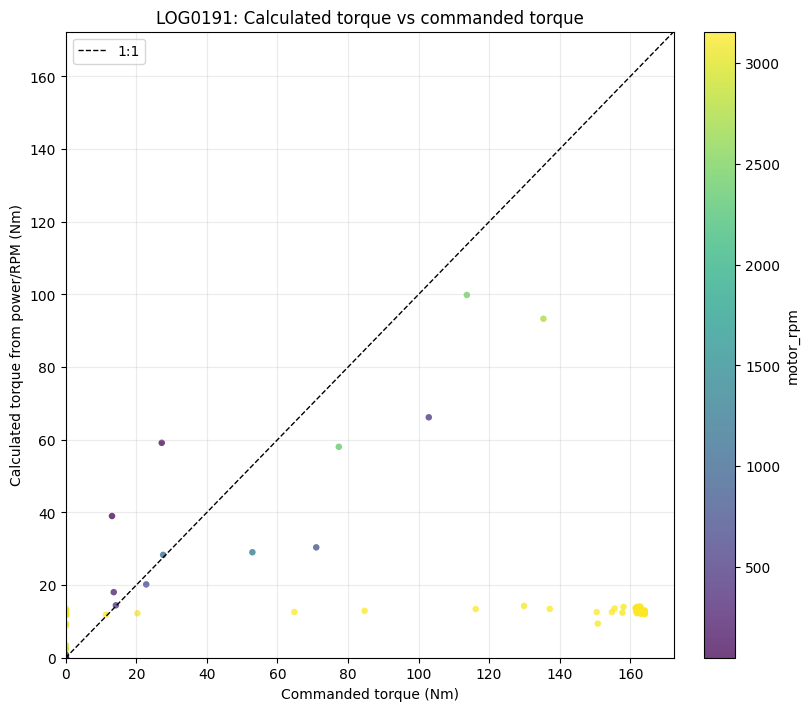

(<Figure size 800x700 with 2 Axes>,
 <Axes: title={'center': 'LOG0191: Calculated torque vs commanded torque'}, xlabel='Commanded torque (Nm)', ylabel='Calculated torque from power/RPM (Nm)'>)

In [72]:
plot_torque_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
    color_by="motor_rpm",
)


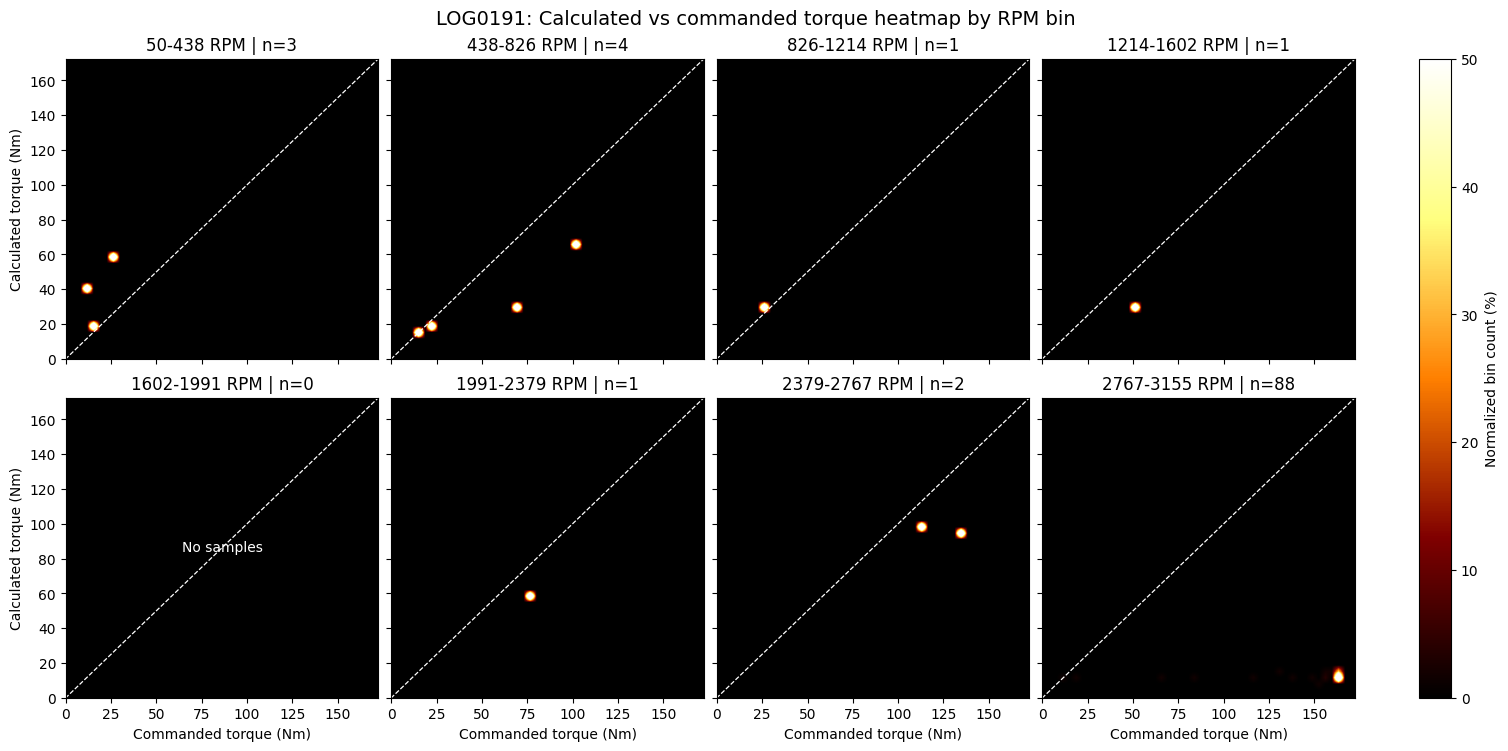

(<Figure size 1500x740 with 9 Axes>,
 array([<Axes: title={'center': '50-438 RPM | n=3'}, ylabel='Calculated torque (Nm)'>,
        <Axes: title={'center': '438-826 RPM | n=4'}>,
        <Axes: title={'center': '826-1214 RPM | n=1'}>,
        <Axes: title={'center': '1214-1602 RPM | n=1'}>,
        <Axes: title={'center': '1602-1991 RPM | n=0'}, xlabel='Commanded torque (Nm)', ylabel='Calculated torque (Nm)'>,
        <Axes: title={'center': '1991-2379 RPM | n=1'}, xlabel='Commanded torque (Nm)'>,
        <Axes: title={'center': '2379-2767 RPM | n=2'}, xlabel='Commanded torque (Nm)'>,
        <Axes: title={'center': '2767-3155 RPM | n=88'}, xlabel='Commanded torque (Nm)'>],
       dtype=object))

In [73]:
plot_torque_heatmaps_by_rpm(
    torque_pairs,
    log_id=log["log_id"],
    rpm_bins=RPM_HEATMAP_BINS,
    torque_bins=TORQUE_HEATMAP_BINS,
)


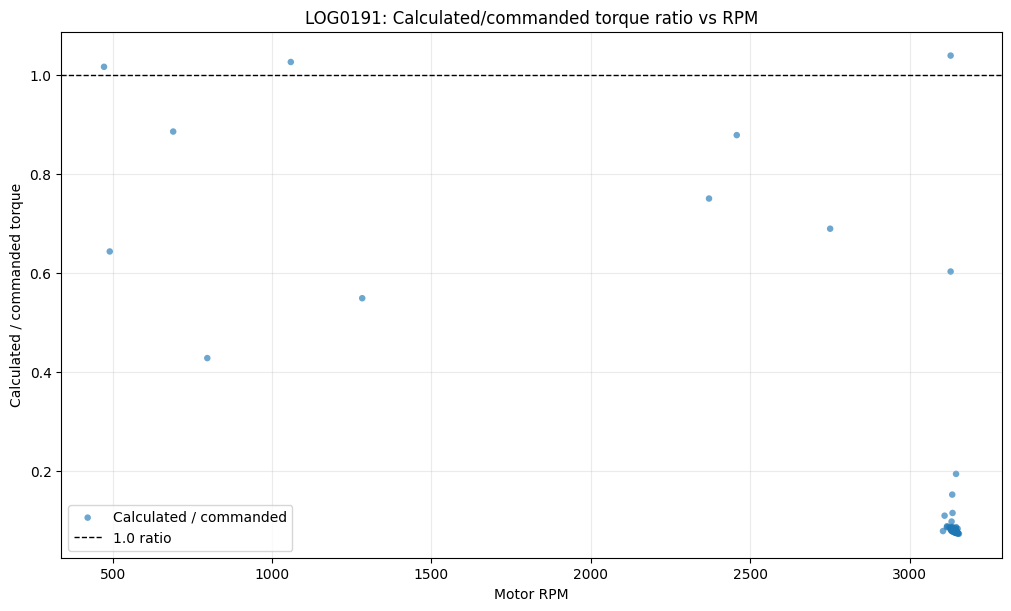

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'LOG0191: Calculated/commanded torque ratio vs RPM'}, xlabel='Motor RPM', ylabel='Calculated / commanded torque'>)

In [74]:
plot_torque_ratio_vs_rpm_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
    min_abs_commanded_torque=MIN_ABS_COMMANDED_TORQUE_FOR_RATIO,
)


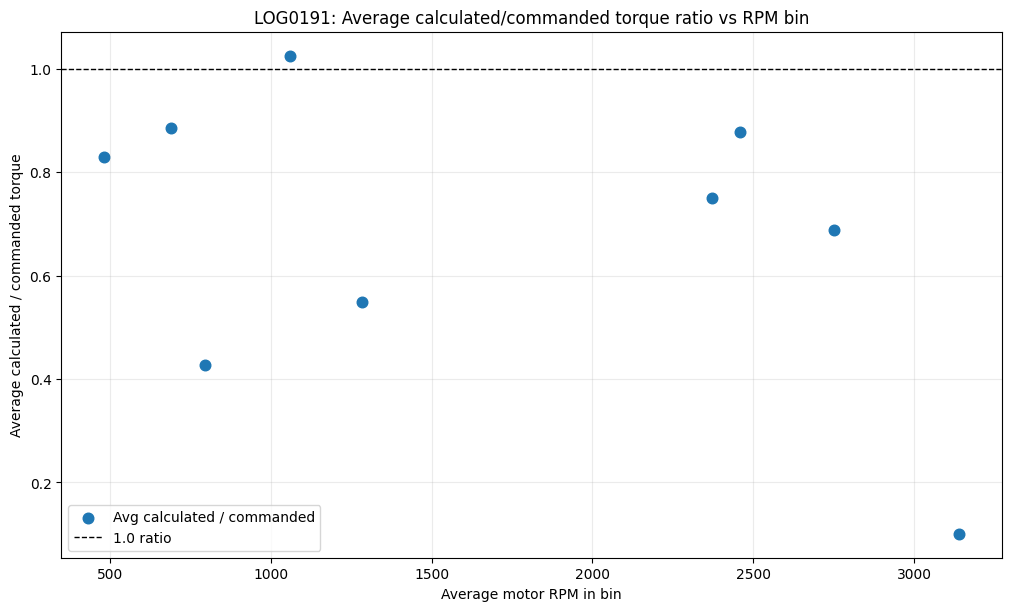

,rpm_bin,rpm_mid,avg_torque_ratio_calc_over_cmd,median_torque_ratio_calc_over_cmd,samples
0,"(472.999, 526.64]",482.000,0.830,0.830,2
1,"(687.56, 741.2]",690.000,0.885,0.885,1
2,"(794.84, 848.48]",797.000,0.428,0.428,1
3,"(1009.4, 1063.04]",1059.000,1.026,1.026,1
4,"(1277.6, 1331.24]",1283.000,0.549,0.549,1
5,"(2350.4, 2404.04]",2371.000,0.750,0.750,1
6,"(2457.68, 2511.32]",2458.000,0.878,0.878,1
7,"(2725.88, 2779.52]",2751.000,0.689,0.689,1
8,"(3101.36, 3155.0]",3138.713,0.100,0.081,87


In [75]:
_fig, _ax, avg_torque_ratio_by_rpm = plot_average_torque_ratio_by_rpm(
    torque_pairs,
    log_id=log["log_id"],
    rpm_bins=AVG_TORQUE_RPM_BINS,
    min_abs_commanded_torque=MIN_ABS_COMMANDED_TORQUE_FOR_RATIO,
)
display(avg_torque_ratio_by_rpm.round(3))


In [76]:
def plot_power_vs_rpm_scatter(torque_pairs, log_id=None, max_points=None):
    plot_df = torque_pairs.dropna(subset=["motor_rpm", "power_kw"]).copy()
    if plot_df.empty:
        raise ValueError("No valid power/RPM pairs to plot.")

    plot_df = _scatter_sample(plot_df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        plot_df["motor_rpm"],
        plot_df["power_kw"],
        s=22,
        alpha=0.65,
        edgecolors="none",
    )

    title = "Power vs RPM"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Motor RPM")
    ax.set_ylabel("Power (kW)")
    ax.grid(True, alpha=0.25)
    plt.show()
    return fig, ax

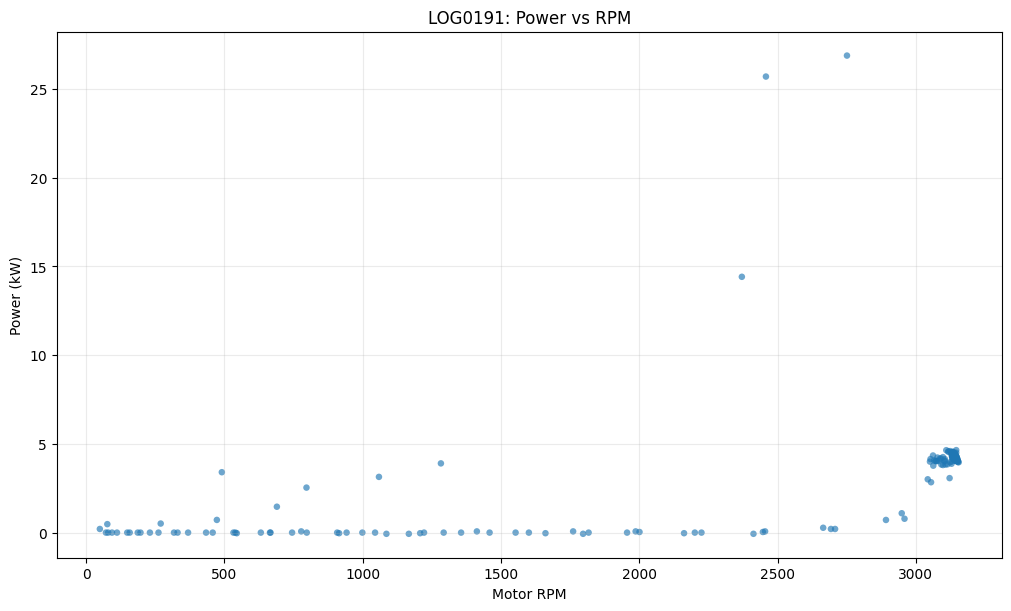

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'LOG0191: Power vs RPM'}, xlabel='Motor RPM', ylabel='Power (kW)'>)

In [77]:
plot_power_vs_rpm_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
)

In [78]:
def plot_torque_vs_rpm_scatter(torque_pairs, log_id=None, max_points=None):
    plot_df = torque_pairs.dropna(subset=["motor_rpm", "calculated_torque_nm"]).copy()
    if plot_df.empty:
        raise ValueError("No valid torque/RPM pairs to plot.")

    plot_df = _scatter_sample(plot_df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        plot_df["motor_rpm"],
        plot_df["calculated_torque_nm"],
        s=22,
        alpha=0.65,
        edgecolors="none",
    )

    title = "Torque vs RPM"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Motor RPM")
    ax.set_ylabel("Torque (Nm)")
    ax.grid(True, alpha=0.25)
    plt.show()
    return fig, ax

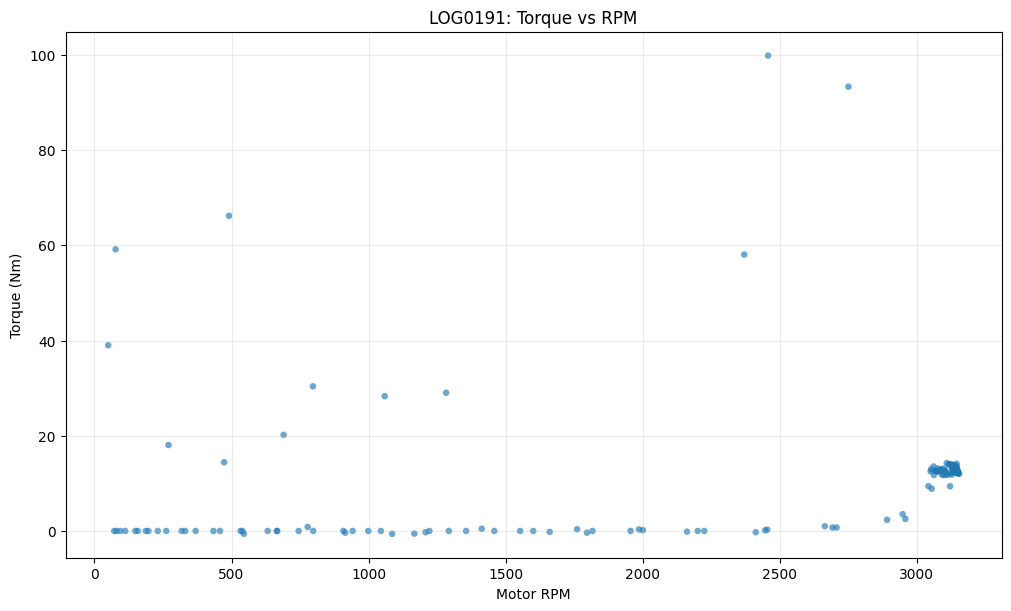

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'LOG0191: Torque vs RPM'}, xlabel='Motor RPM', ylabel='Torque (Nm)'>)

In [79]:
plot_torque_vs_rpm_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
)